# 极客项目 ch05：类鸟群 Boids

对应《Python Playground》第 5 章（Simulating a Boid Flock）。`FuncAnimation` 动画与鼠标事件 cell 保留但不执行；用固定种子（2028）的静态帧演示替代。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.spatial.distance import squareform, pdist, cdist
from numpy.linalg import norm

np.random.seed(2028)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

width, height = 640, 480

## 书 5.3.1–5.3.8 Boids 类

位置/速度初始化（5.3.1）、平铺边界 `applyBC`（5.3.2）、三规则 `applyRules`（5.3.4）、鼠标事件 `buttonPress`（5.3.5/5.3.6）、每帧流水线 `tick` 与限速（5.3.8）都在一个类里。

In [2]:
# ===== 书 5.3.1–5.3.8 节 Boids 类 =====
class Boids:
    """Class that represents Boids simulation"""
    def __init__(self, N):
        """ initialize the Boid simulation"""
        # init position & velocities
        self.pos = [width/2.0, height/2.0] + 10*np.random.rand(2*N).reshape(N, 2)
        # normalized random velocities
        angles = 2*math.pi*np.random.rand(N)
        self.vel = np.array(list(zip(np.sin(angles), np.cos(angles))))
        self.N = N
        # min dist of approach
        self.minDist = 25.0
        # max magnitude of velocities calculated by "rules"
        self.maxRuleVel = 0.03
        # max magnitude of final velocity
        self.maxVel = 2.0

    def tick(self, frameNum, pts, beak):
        """Update the simulation by one time step."""
        # get pairwise distances
        self.distMatrix = squareform(pdist(self.pos))
        # apply rules
        self.vel += self.applyRules()
        self.limit(self.vel, self.maxVel)
        self.pos += self.vel
        self.applyBC()
        # update data
        pts.set_data(self.pos.reshape(2*self.N)[::2],
                     self.pos.reshape(2*self.N)[1::2])
        vec = self.pos + 10*self.vel/self.maxVel
        beak.set_data(vec.reshape(2*self.N)[::2],
                      vec.reshape(2*self.N)[1::2])

    def limitVec(self, vec, maxVal):
        """limit magnitude of 2D vector"""
        mag = norm(vec)
        if mag > maxVal:
            vec[0], vec[1] = vec[0]*maxVal/mag, vec[1]*maxVal/mag

    def limit(self, X, maxVal):
        """limit magnitude of 2D vectors in array X to maxVal"""
        for vec in X:
            self.limitVec(vec, maxVal)

    def applyBC(self):
        """apply boundary conditions"""
        deltaR = 2.0
        for coord in self.pos:
            if coord[0] > width + deltaR:
                coord[0] = -deltaR
            if coord[0] < -deltaR:
                coord[0] = width + deltaR
            if coord[1] > height + deltaR:
                coord[1] = -deltaR
            if coord[1] < -deltaR:
                coord[1] = height + deltaR

    def applyRules(self):
        # rule #1 - Separation
        D = self.distMatrix < 25.0
        vel = self.pos*D.sum(axis=1).reshape(self.N, 1) - D.dot(self.pos)
        self.limit(vel, self.maxRuleVel)

        # different distance threshold
        D = self.distMatrix < 50.0

        # rule #2 - Alignment
        vel2 = D.dot(self.vel)
        self.limit(vel2, self.maxRuleVel)
        vel += vel2

        # rule #3 - Cohesion  # 原书笔误：注释写成 rule #1
        vel3 = D.dot(self.pos) - self.pos
        self.limit(vel3, self.maxRuleVel)
        vel += vel3

        return vel

    def buttonPress(self, event):
        """event handler for matplotlib button presses"""
        # left click - add a boid
        if event.button == 1:  # Py3：is 1→==1
            self.pos = np.concatenate((self.pos,
                                       np.array([[event.xdata, event.ydata]])),
                                      axis=0)
            # random velocity
            angles = 2*math.pi*np.random.rand(1)
            v = np.array(list(zip(np.sin(angles), np.cos(angles))))
            self.vel = np.concatenate((self.vel, v), axis=0)
            self.N += 1
        # right click - scatter
        elif event.button == 3:  # Py3：is 3→==3
            # add scattering velocity
            self.vel += 0.1*(self.pos - np.array([[event.xdata, event.ydata]]))


## 书 5.3.8 模块级 tick——动画回调

把类方法包成 `FuncAnimation` 需要的回调签名。

In [3]:
# ===== 书 5.3.8 节 模块级 tick() =====
def tick(frameNum, pts, beak, boids):
    """update function for animation"""
    boids.tick(frameNum, pts, beak)
    return pts, beak


## 组装动画（FuncAnimation，不执行）

> 原书 main() 用 `FuncAnimation` 逐帧推进并响应鼠标点击（左键加鸟、右键驱散），无头环境不执行；argparse 略。

In [ ]:
# ===== 书 5.3.8 节 组装动画（不执行：GUI 动画 + 鼠标事件）=====
# number of boids
N = 100

# create boids
boids = Boids(N)

# setup plot
fig = plt.figure()
ax = plt.axes(xlim=(0, width), ylim=(0, height))

pts, = ax.plot([], [], markersize=10,
               c='k', marker='o', ls='None')
beak, = ax.plot([], [], markersize=4,
                c='r', marker='o', ls='None')
anim = animation.FuncAnimation(fig, tick, fargs=(pts, beak, boids),
                               interval=50)

# add a "button press" event handler
cid = fig.canvas.mpl_connect('button_press_event', boids.buttonPress)

plt.show()

## 演示：静态帧

150 个个体，t=0/50/150 三帧：三规则让随机散布的鸟群聚成群（黑点=身体，红点=喙；seed=2028）。

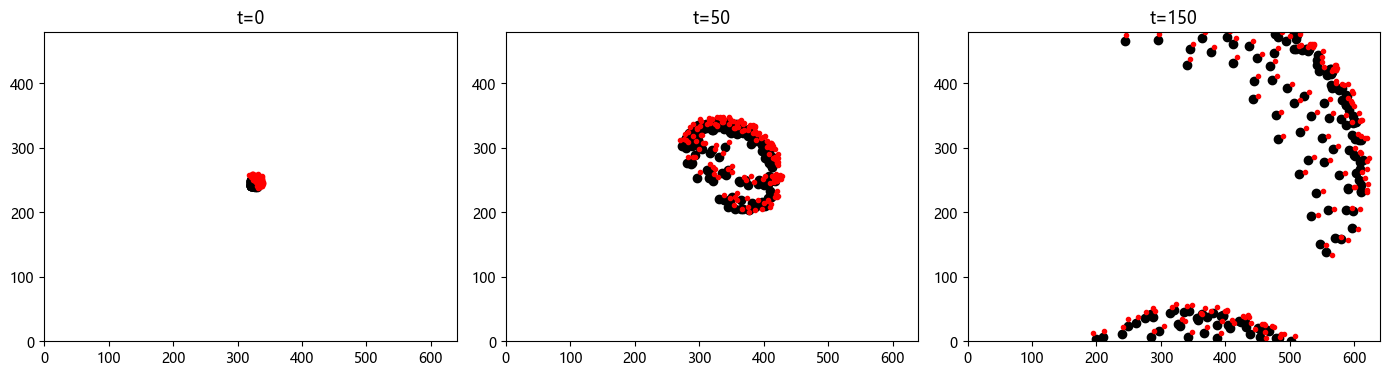

In [4]:
# ===== 演示：静态帧（FuncAnimation 的离线替代）=====
np.random.seed(2028)

class _Stub:                           # 吃掉 tick() 里的 set_data()
    def set_data(self, *_):
        pass

N = 150
boids = Boids(N)
snaps = [(0, boids.pos.copy())]
for t in range(1, 151):
    boids.tick(t, _Stub(), _Stub())
    if t in (50, 150):
        snaps.append((t, boids.pos.copy()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for axi, (t, pos) in zip(axes, snaps):
    axi.plot(pos.reshape(2*boids.N)[::2], pos.reshape(2*boids.N)[1::2],
             markersize=6, c='k', marker='o', ls='None')
    vec = pos + 10*boids.vel/boids.maxVel
    axi.plot(vec.reshape(2*boids.N)[::2], vec.reshape(2*boids.N)[1::2],
             markersize=3, c='r', marker='o', ls='None')
    axi.set_xlim(0, width); axi.set_ylim(0, height)
    axi.set_aspect('equal')
    axi.set_title('t=%d' % t)
plt.tight_layout()
plt.show()